# Visualize model performance

We plot the precision-recall curves, the distribution of predicted probabilities, and the accuracy per biological replicate for the TGF-β versus vehicle model.

In [1]:
suppressPackageStartupMessages({
    library(ggplot2)
    library(tidyr)
    library(dplyr)
    library(arrow)
    library(ggridges)
})

Warning message:
“package ‘ggplot2’ was built under R version 4.2.3”


Warning message:
“package ‘tidyr’ was built under R version 4.2.3”


Warning message:
“package ‘arrow’ was built under R version 4.2.3”


Warning message:
“package ‘ggridges’ was built under R version 4.2.3”


In [2]:
output_dir <- file.path("figures")
if (!dir.exists(output_dir)) {
    dir.create(output_dir, recursive = TRUE)
}

# Colors for the data splits (distinct from the treatment colors) and treatments
dataset_colors <- c(
    "train" = "#6250d6",
    "test" = "#e87ba4",
    "holdout" = "#1baf7a",
    "holdout_replicate" = "#1baf7a",
    "holdout_well" = "#eda100"
)
treatment_colors <- c("TGFB" = "#eb6834", "Veh" = "#2a78d6")

## Precision-recall curves

In [3]:
pr_results <- read_parquet(file.path("performance_metrics", "all_models_pr_curve_results.parquet")) %>%
    mutate(dataset = factor(dataset, levels = c("train", "test", "holdout")))

head(pr_results)

precision,recall,model_type,dataset,model_name
<dbl>,<dbl>,<chr>,<fct>,<chr>
0.5000000,1,final,train,model_TGFB_vs_Veh
0.5001045,1,final,train,model_TGFB_vs_Veh
0.5002090,1,final,train,model_TGFB_vs_Veh
0.5003136,1,final,train,model_TGFB_vs_Veh
0.5004182,1,final,train,model_TGFB_vs_Veh
0.5005229,1,final,train,model_TGFB_vs_Veh


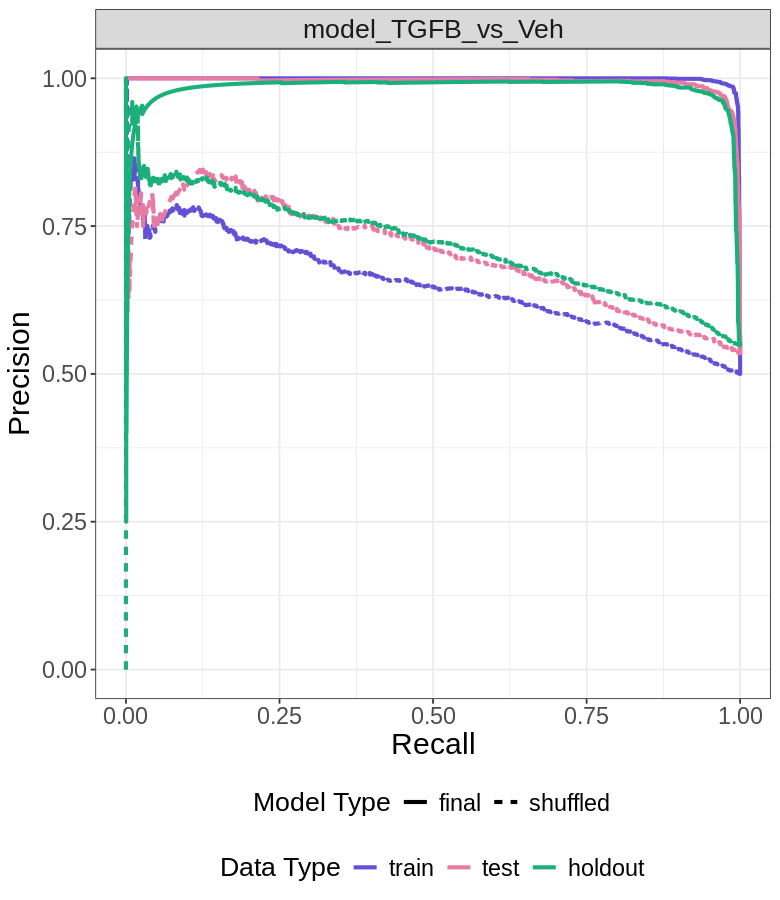

In [4]:
width <- 6.5
height <- 7.5
options(repr.plot.width = width, repr.plot.height = height)

# Create the ggplot for PR curves
all_models_pr_curves <- ggplot(pr_results, aes(x = recall, y = precision, color = dataset, linetype = model_type)) +
    geom_line(linewidth = 1.15) +
    facet_wrap(model_name ~ .) +
    scale_color_manual(values = dataset_colors) +
    labs(
        x = "Recall",
        y = "Precision",
        color = "Data Type",
        linetype = "Model Type"
    ) +
    theme_bw() +
    theme(
        text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 14),
        legend.title = element_text(size = 16),
        legend.text = element_text(size = 14),
        strip.text = element_text(size = 16),
        legend.position = "bottom",
        legend.box = "vertical"
    )

# Save the plot to the output directory
ggsave(file.path(output_dir, "all_models_pr_curves.png"), all_models_pr_curves, dpi = 500, height = height, width = width)

all_models_pr_curves

## Predicted probabilities

In [5]:
probability_results <- read_parquet(file.path("performance_metrics", "all_models_predicted_probabilities.parquet"))

head(probability_results)

# Print the number of cells per biological replicate
cat("\nCounts per Metadata_N_Replicate:\n")
print(table(probability_results$Metadata_N_Replicate, probability_results$dataset))

actual_label,predicted_probability,Metadata_N_Replicate,Metadata_Well,Metadata_holdout_type,model_type,dataset,model_name
<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
TGFB,0.0003447276,N1,B05,NA,final,train,model_TGFB_vs_Veh
TGFB,0.0001209513,N4,C08,NA,final,train,model_TGFB_vs_Veh
TGFB,0.0039993558,N2,C03,NA,final,train,model_TGFB_vs_Veh
TGFB,0.0102148642,N1,B10,NA,final,train,model_TGFB_vs_Veh
TGFB,0.1527971493,N1,F06,NA,final,train,model_TGFB_vs_Veh
TGFB,0.0026441636,N4,G06,NA,final,train,model_TGFB_vs_Veh



Counts per Metadata_N_Replicate:


    
     holdout test train
  N1    1404 1694  3720
  N2     926 1256  2714
  N3    5196    0     0
  N4    1012 1464  3138


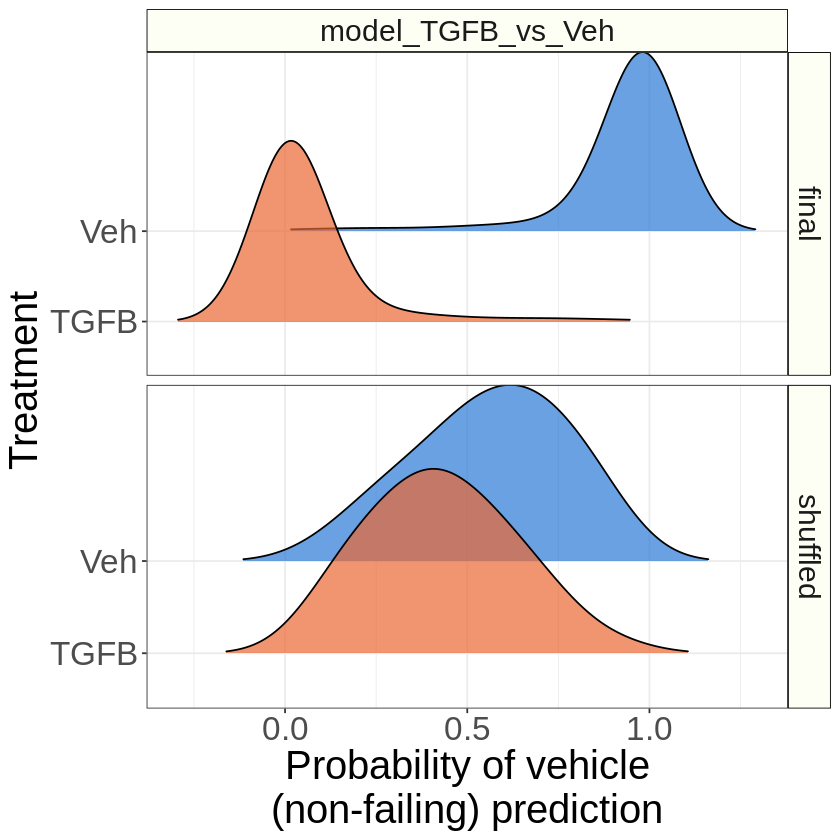

In [6]:
# Filter the data for test data only
test_performance_df <- probability_results[probability_results$dataset %in% c("test"), ]

height <- 7
width <- 7
options(repr.plot.width = width, repr.plot.height = height)

ridge_plot_test <- ggplot(test_performance_df, aes(x = predicted_probability, y = actual_label, fill = actual_label)) +
    geom_density_ridges(alpha = 0.7, scale = 2, rel_min_height = 0.01, bandwidth = 0.1) +
    scale_fill_manual(values = treatment_colors) +
    scale_x_continuous(breaks = seq(0, 1, 0.5)) +
    facet_grid(model_type ~ model_name, scales = "free_y") +
    labs(x = "Probability of vehicle\n(non-failing) prediction", y = "Treatment") +
    theme_bw() +
    theme(
        legend.position = "none",
        axis.text = element_text(size = 20),
        axis.text.x = element_text(size = 20),
        axis.title = element_text(size = 24),
        strip.text = element_text(size = 18),
        strip.background = element_rect(
            colour = "black",
            fill = "#fdfff4"
        )
    )

# Save the plot to the output directory
ggsave(file.path(output_dir, "prob_ridge_plot_testing_data.png"), ridge_plot_test, dpi = 500, height = height, width = width)

ridge_plot_test

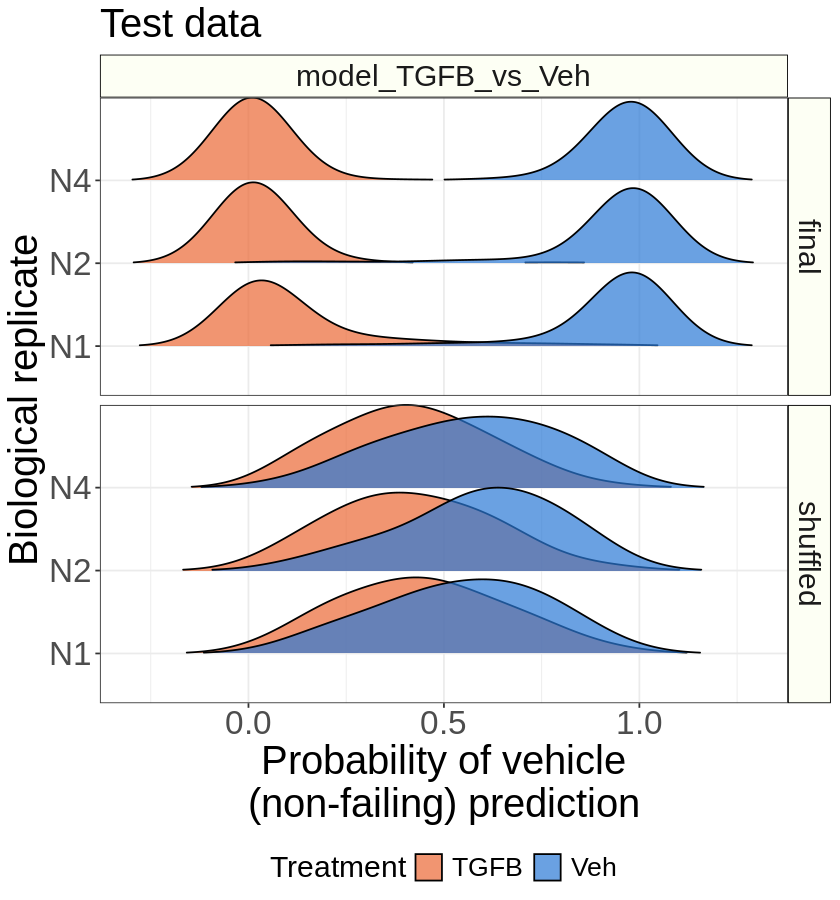

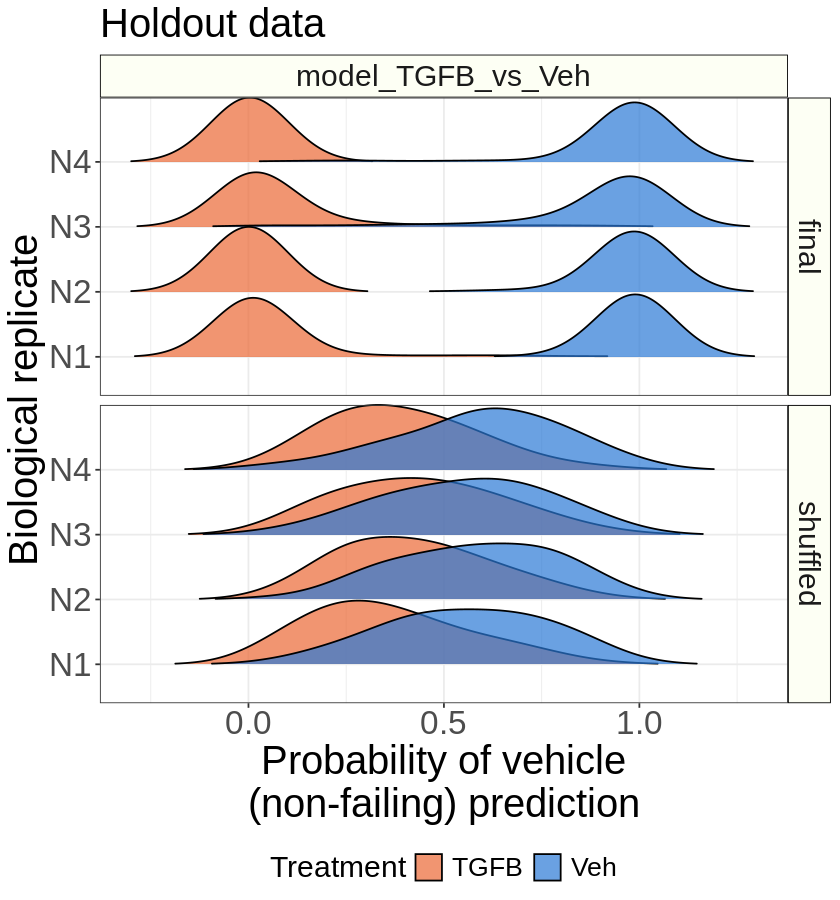

In [7]:
# Plot predicted probabilities per biological replicate for test and holdout data
for (split in c("test", "holdout")) {
    split_df <- probability_results[probability_results$dataset == split, ]

    height <- 7.5
    width <- 7
    options(repr.plot.width = width, repr.plot.height = height)

    ridge_plot <- ggplot(split_df, aes(x = predicted_probability, y = Metadata_N_Replicate, fill = actual_label)) +
        geom_density_ridges(alpha = 0.7, scale = 1, rel_min_height = 0.01, bandwidth = 0.1) +
        scale_fill_manual(values = treatment_colors) +
        scale_x_continuous(breaks = seq(0, 1, 0.5)) +
        facet_grid(model_type ~ model_name, scales = "free_y") +
        labs(
            x = "Probability of vehicle\n(non-failing) prediction",
            y = "Biological replicate",
            fill = "Treatment",
            title = paste0(tools::toTitleCase(split), " data")
        ) +
        theme_bw() +
        theme(
            axis.text = element_text(size = 20),
            axis.title = element_text(size = 24),
            plot.title = element_text(size = 24),
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16),
            legend.position = "bottom",
            strip.text = element_text(size = 18),
            strip.background = element_rect(
                colour = "black",
                fill = "#fdfff4"
            )
        )

    # Save the plot to the output directory
    ggsave(file.path(output_dir, paste0("prob_ridge_plot_per_replicate_", split, "_data.png")), ridge_plot, dpi = 500, height = height, width = width)

    print(ridge_plot)
}

## Accuracy per biological replicate

In [8]:
# Compute accuracy per biological replicate, per treatment, per split, per model
accuracy_per_replicate <- probability_results %>%
    mutate(
        predicted_binary = ifelse(predicted_probability >= 0.5, 1L, 0L),
        actual_binary = as.integer(actual_label == "Veh"),
        dataset_modified = case_when(
            dataset == "holdout" ~ paste0("holdout_", Metadata_holdout_type),
            TRUE ~ dataset
        )
    ) %>%
    group_by(model_name, model_type, dataset_modified, Metadata_N_Replicate, actual_label) %>%
    summarize(
        accuracy = mean(predicted_binary == actual_binary, na.rm = TRUE),
        n = n(),
        .groups = "drop"
    ) %>%
    # Ensure desired order for the dataset factor so bars appear in train, test, holdout order
    mutate(dataset_modified = factor(dataset_modified, levels = c("train", "test", "holdout_well", "holdout_replicate")))

accuracy_per_replicate

# Save accuracy results
write_parquet(accuracy_per_replicate, file.path("performance_metrics", "accuracy_per_replicate.parquet"))

model_name,model_type,dataset_modified,Metadata_N_Replicate,actual_label,accuracy,n
<chr>,<chr>,<fct>,<chr>,<chr>,<dbl>,<int>
model_TGFB_vs_Veh,final,holdout_replicate,N3,TGFB,0.9544211,1097
model_TGFB_vs_Veh,final,holdout_replicate,N3,Veh,0.9327115,1501
model_TGFB_vs_Veh,final,holdout_well,N1,TGFB,0.9633028,327
model_TGFB_vs_Veh,final,holdout_well,N1,Veh,0.9920000,375
model_TGFB_vs_Veh,final,holdout_well,N2,TGFB,1.0000000,203
model_TGFB_vs_Veh,final,holdout_well,N2,Veh,0.9884615,260
model_TGFB_vs_Veh,final,holdout_well,N4,TGFB,1.0000000,300
model_TGFB_vs_Veh,final,holdout_well,N4,Veh,0.9660194,206
model_TGFB_vs_Veh,final,test,N1,TGFB,0.9352941,340


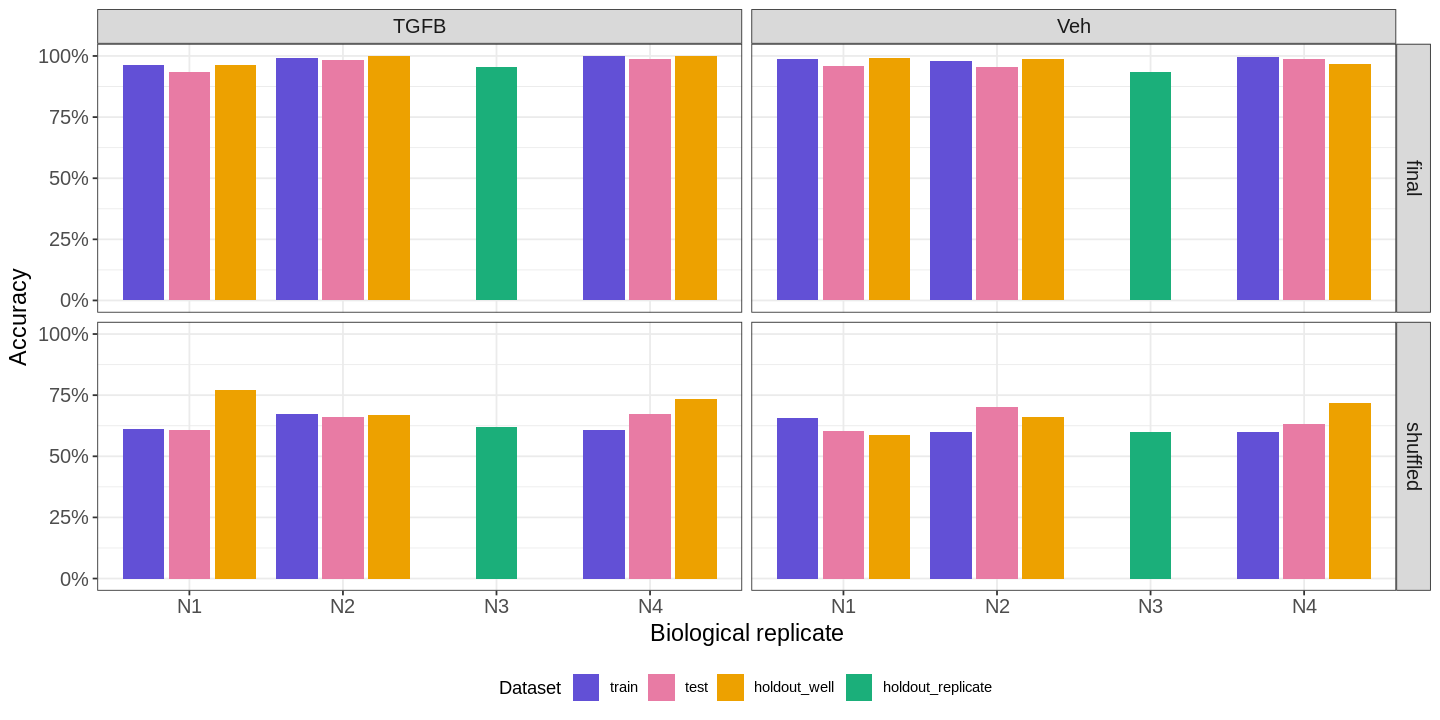

In [9]:
# Plot accuracy per biological replicate with modified dataset
height <- 6
width <- 12
options(repr.plot.width = width, repr.plot.height = height)

accuracy_barplot <- ggplot(
    accuracy_per_replicate,
    aes(x = Metadata_N_Replicate, y = accuracy, fill = dataset_modified)
) +
    geom_col(position = position_dodge2(preserve = "single", padding = 0.1)) +
    facet_grid(model_type ~ actual_label) +
    scale_fill_manual(values = dataset_colors) +
    scale_y_continuous(labels = scales::percent_format(accuracy = 1), limits = c(0, 1)) +
    labs(
        x = "Biological replicate",
        y = "Accuracy",
        fill = "Dataset"
    ) +
    theme_bw() +
    theme(
        axis.text.x = element_text(size = 12),
        axis.text.y = element_text(size = 12),
        axis.title = element_text(size = 14),
        strip.text = element_text(size = 12),
        legend.position = "bottom"
    )

# Save plot
ggsave(file.path(output_dir, "accuracy_per_replicate_by_model.png"), accuracy_barplot, dpi = 600, width = width, height = height)

accuracy_barplot